## Rama B — Capítulo 2

Este cuaderno genera las figuras de la Rama B (semilla a 852 nm, señal a 794 nm) a partir de las expresiones del Capítulo 2. Cada sección indica qué cantidad física se grafica, de qué ecuación sale, cómo se normaliza y qué conviene observar en la gráfica.

| Figura del cuaderno | Figura del PDF | Cantidad | Archivo |
|---|---|---|---|
| F1 | — | $\rho_{bb}^{(2)}$ frente a $\Delta_3$, (2.52)–(2.53) | `figuras/F1_rhobb_vs_delta3.pdf` |
| F2 | 2.7 | $\chi_{\text{pop}}(\omega_2)$ frente a $\delta_2$, (2.86) | `figuras/F2_chipop_vs_delta2.pdf` |
| F3 | 2.8 | mapa de $\mathrm{Im}\,\chi^{(3)}_{\text{pop}}$, (2.87) | `figuras/F3_mapa_chipop.pdf` |
| F4 | 2.9 | $\chi_{\text{ef}}$ de la señal, término por término, (2.85) y (2.87) | `figuras/F4_chief_terminos.pdf` |
| F5 | 2.6 | módulo y fase de $\chi^{(3)}_{P,B}$, (2.84) | `figuras/F5_chiP_modulo_fase.pdf` |

**Convenciones**

- Todas las tasas y desintonías se ingresan **divididas por $2\pi$, en MHz**. Como cada figura usa cocientes entre frecuencias, el factor $2\pi$ se cancela.
- Las constantes físicas se importan de `constants.py` (raíz del repositorio), que está en SI y rad/s, y se convierten a MHz dividiendo por $2\pi\times10^6$.
- Las figuras se guardan en `figuras/` en formato PDF.

In [1]:
import os
import sys
sys.path.append('../..')  # carpeta raíz del repositorio, donde está constants.py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from constants import g_ba, g_ca, g_cb, G_ab, w_ba, w_ca, w_cb

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

os.makedirs("figuras", exist_ok=True)

def guardar(fig, nombre):
    # Guarda la figura en figuras/<nombre>.pdf
    ruta = os.path.join("figuras", f"{nombre}.pdf")
    fig.savefig(ruta, bbox_inches="tight")
    print(f"Guardada: {ruta}")

## 1. Parámetros del modelo

Las cantidades que aparecen en las susceptibilidades de la Rama B son:

| Símbolo | Significado | Dónde aparece |
|---|---|---|
| $\Gamma_{ab}$ | tasa de decaimiento de población $\lvert b\rangle\to\lvert a\rangle$ | $\rho_{bb}^{(2)}$, (2.52) |
| $\gamma_{ba}$ | tasa de decaimiento de la coherencia $\rho_{ba}$ | todas las resonancias de la semilla |
| $\gamma_{ca}$ | tasa de decaimiento de la coherencia de dos fotones $\rho_{ca}$ | resonancia de dos fotones |
| $\gamma_{cb}$ | tasa de decaimiento de la coherencia $\rho_{cb}$ | resonancia de la señal |
| $\Delta_1$ | desintonía del bombeo respecto de $\lvert a\rangle\to\lvert b\rangle$, **con su signo**, (2.6) | $\chi^{(3)}_{X,B}$ y $\chi^{(3)}_{P,B}$ |

Las cuatro tasas se importan de `constants.py` (`g_ba`, `g_ca`, `g_cb`, `G_ab`). Allí $\Gamma_{ab}$ y $\gamma_{cb}$ se definen suponiendo decaimiento puramente radiativo, $\gamma_{ij} = (\Gamma_i+\Gamma_j)/2$ con $\Gamma_a = 0$:

$$
\Gamma_{ab} = \Gamma_b = 2\gamma_{ba},
\qquad
\gamma_{cb} = \frac{\Gamma_b+\Gamma_c}{2} = \gamma_{ba}+\gamma_{ca}.
$$

$\Delta_1$ no es un parámetro libre: queda fijado por la perilla $\Delta_2$ del bombeo y se calcula con `desintonias` (sección 2).

Los prefactores $N$, $\mu_{ba}$, $\mu_{cb}$, $\varepsilon_0$, $\hbar$ y las amplitudes de los campos no hacen falta: cada figura se normaliza de modo que se cancelen.

Las opciones de graficación (rango de los ejes, número de puntos, desintonía fija de la semilla en la Figura F4) no son constantes físicas y pueden ajustarse libremente.

In [2]:
# --- Constantes físicas, desde constants.py ---------------------------------
# constants.py está en rad/s; aquí todo va dividido por 2π, en MHz.
MHz = 2 * np.pi * 1e6   # rad/s que corresponden a 1 MHz de ω/2π

gamma_ba = g_ba / MHz             # γ_ba/2π : decaimiento de la coherencia ρ_ba (Γ_D2/2)
gamma_ca = g_ca / MHz             # γ_ca/2π : decaimiento de la coherencia de dos fotones ρ_ca
Gamma_ab = G_ab / MHz             # Γ_ab/2π : decaimiento de población |b> -> |a> (= Γ_D2)
gamma_cb = g_cb / MHz             # γ_cb/2π : decaimiento de la coherencia ρ_cb, (Γ_b + Γ_c)/2

# Frecuencias de transición /2π, en MHz (las usa `desintonias`)
nu_ba, nu_ca, nu_cb = w_ba / MHz, w_ca / MHz, w_cb / MHz

# --- Opciones de graficación -----------------------------------------------
N_ANCHOS    = 8      # semiancho de cada eje, en múltiplos del ancho relevante
N_PUNTOS    = 2001   # resolución de las curvas
N_MAPA      = 601    # resolución de los mapas
DELTA3_FIJA = 3.0    # Figura F4: desintonía de la semilla del segundo panel, en múltiplos de γ_ba

print(f"Gamma_ab/2pi = {Gamma_ab:.4f} MHz   gamma_ba/2pi = {gamma_ba:.4f} MHz")
print(f"gamma_ca/2pi = {gamma_ca:.4f} MHz   gamma_cb/2pi = {gamma_cb:.4f} MHz")

Gamma_ab/2pi = 5.2227 MHz   gamma_ba/2pi = 2.6113 MHz
gamma_ca/2pi = 0.7652 MHz   gamma_cb/2pi = 3.3765 MHz


In [3]:
def verificar():
    # Detiene la ejecución si alguna constante física sigue pendiente.
    pendientes = [nombre for nombre in ("Gamma_ab", "gamma_ba", "gamma_ca", "gamma_cb")
                  if globals()[nombre] is None]
    if pendientes:
        raise ValueError("Faltan constantes por definir en la sección 1: " + ", ".join(pendientes))

## 2. Desintonías que se controlan en la Rama B

En la Rama B el experimentador sintoniza dos láseres: el bombeo de 822 nm, con desintonía de dos fotones $\Delta_2$, y la semilla de 852 nm, con desintonía $\Delta_3$. La desintonía de la señal de 794 nm no es independiente; por la conservación de la energía, (2.8),

$$
\delta_2 = \Delta_2 - \Delta_3 .
$$

Las dos perillas se parametrizan con

* $\Delta_2 = \omega_{ca} - 2\omega_1$: desintonía de dos fotones del bombeo, (2.6);
* $\Delta_3 = \omega_{ba} - \omega_3$: desintonía de la semilla respecto de la D2.

Invirtiendo estas definiciones se obtienen $\omega_1$ y $\omega_3$; la conservación de la energía fija $\omega_2 = 2\omega_1 - \omega_3$, y de ahí salen las otras dos desintonías:

$$
\Delta_1 = \omega_{ba} - \omega_1 = \Bigl(\omega_{ba} - \tfrac{\omega_{ca}}{2}\Bigr) + \tfrac{\Delta_2}{2},
\qquad
\delta_2 = \omega_{cb} - \omega_2 = \Delta_2 - \Delta_3 .
$$

La función `desintonias(D2, D3)` hace este cálculo y devuelve $(\Delta_1, \delta_2)$. $\Delta_1$ depende solo del bombeo y es del orden de THz (la celda de abajo lo imprime): el 822 nm está al azul de la D2, de modo que $\lvert\Delta_1\rvert \gg \gamma_{ba}$.

Por eso los mapas de este cuaderno usan $(\Delta_2,\Delta_3)$ como ejes, y en ellos se marcan tres rectas:

- $\Delta_2 = 0$: resonancia de dos fotones $\lvert a\rangle\to\lvert c\rangle$;
- $\Delta_3 = 0$: semilla en resonancia con la línea D2;
- $\delta_2 = 0$, es decir $\Delta_3 = \Delta_2$: señal en resonancia con $\lvert b\rangle\to\lvert c\rangle$.

La función auxiliar `lorentziana` es el perfil normalizado a 1 en su centro,

$$
L_\gamma(x) = \frac{\gamma^2}{x^2+\gamma^2},
$$

que aparece en todas las figuras.

In [4]:
def frecuencias_laser(D2, D3):
    # Frecuencias /2π (MHz) de los tres campos a partir de las dos perillas (Δ2, Δ3)
    nu1 = (nu_ca - D2) / 2    # bombeo, 822 nm
    nu3 = nu_ba - D3          # semilla, 852 nm
    nu2 = 2 * nu1 - nu3       # señal, 794 nm: conservación de la energía (2.5)
    return nu1, nu2, nu3

def desintonias(D2, D3):
    # Devuelve (Δ1, δ2) según (2.6) y (2.8)
    nu1, nu2, nu3 = frecuencias_laser(D2, D3)
    D1 = nu_ba - nu1
    d2 = D2 - D3              # = nu_cb - nu2, sin el redondeo de restar números ~1e8 MHz
    return D1, d2

def delta2(D2, D3):
    # Desintonía de la señal, ec. (2.8).
    return desintonias(D2, D3)[1]

def lorentziana(x, gamma):
    # Perfil lorentziano normalizado a 1 en x = 0.
    return gamma**2 / (x**2 + gamma**2)

def marcar_rectas(ax, lim):
    # Marca Δ2 = 0, Δ3 = 0 y δ2 = 0 sobre un mapa con ejes (Δ2, Δ3).
    ax.axvline(0, color="w", ls="--", lw=1)
    ax.axhline(0, color="w", ls=":", lw=1.2)
    ax.plot([-lim, lim], [-lim, lim], color="w", ls="-.", lw=1)
    ax.text(0.02 * lim, 0.9 * lim, r"$\Delta_2=0$", color="w")
    ax.text(0.55 * lim, 0.04 * lim, r"$\Delta_3=0$", color="w")
    ax.text(0.45 * lim, 0.58 * lim, r"$\delta_2=0$", color="w", rotation=45)

D1_0, _ = desintonias(0.0, 0.0)
print(f"Delta1/2pi (Delta2 = 0) = {D1_0 / 1e6:.4f} THz   |Delta1|/gamma_ba = {abs(D1_0) / gamma_ba:.1e}")

Delta1/2pi (Delta2 = 0) = -12.7792 THz   |Delta1|/gamma_ba = 4.9e+06


## 3. Figura F1 — La población $\rho_{bb}^{(2)}$ que crea la semilla

**Cantidad.** La población de segundo orden del nivel intermedio, (2.52)–(2.53),

$$
\rho_{bb}^{(2)} = \frac{2\gamma_{ba}}{\Gamma_{ab}}\,\lvert A_3\rvert^2,
\qquad
\lvert A_3\rvert^2 = \frac{\lvert\mu_{ba}\tilde E_3\rvert^2}{\hbar^2\,(\Delta_3^2+\gamma_{ba}^2)} .
$$

**Normalización.** Se divide por $\lvert A_3\rvert^2$ en resonancia, $\lvert\mu_{ba}\tilde E_3\rvert^2/(\hbar\gamma_{ba})^2$, de modo que la intensidad de la semilla se cancela:

$$
\frac{\rho_{bb}^{(2)}}{\lvert A_3\rvert^2_{\Delta_3=0}} = \frac{2\gamma_{ba}}{\Gamma_{ab}}\;L_{\gamma_{ba}}(\Delta_3).
$$

Junto a ella se grafica la parte imaginaria de $\chi^{(1)}(\omega_3)$, (2.79), con la misma normalización que la Figura 2.5:

$$
\frac{\gamma_{ba}\,\mathrm{Im}\,\chi^{(1)}(\omega_3)}{N\lvert\mu_{ba}\rvert^2/\varepsilon_0\hbar} = L_{\gamma_{ba}}(\Delta_3).
$$

**Qué observar.** Ambas curvas tienen la misma forma: la población que la semilla deja en $\lvert b\rangle$ sigue su propia línea de absorción. Solo difieren en el factor de escala $2\gamma_{ba}/\Gamma_{ab}$.

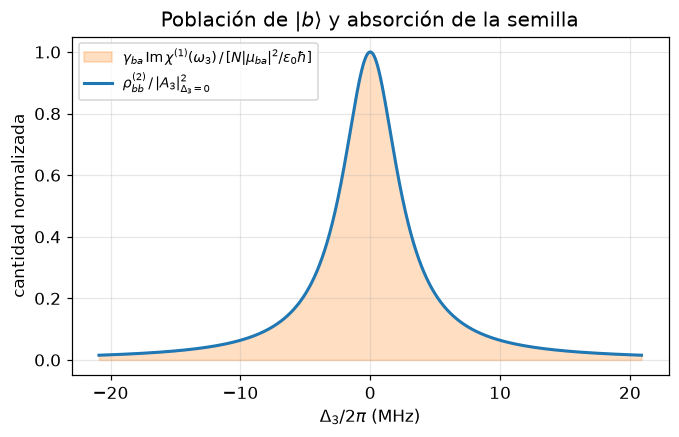

Guardada: figuras\F1_rhobb_vs_delta3.pdf


In [5]:
verificar()

D3 = np.linspace(-N_ANCHOS * gamma_ba, N_ANCHOS * gamma_ba, N_PUNTOS)

rho_bb_norm = (2 * gamma_ba / Gamma_ab) * lorentziana(D3, gamma_ba)
im_chi1_norm = lorentziana(D3, gamma_ba)

fig, ax = plt.subplots(figsize=(7, 4))
# La absorción se dibuja como área sombreada para que se distinga aunque ambas curvas coincidan.
ax.fill_between(D3, im_chi1_norm, color="C1", alpha=0.25,
        label=r"$\gamma_{ba}\,\mathrm{Im}\,\chi^{(1)}(\omega_3)\,/\,[N|\mu_{ba}|^2/\varepsilon_0\hbar]$")
ax.plot(D3, rho_bb_norm, color="C0", lw=2, label=r"$\rho_{bb}^{(2)}\,/\,|A_3|^2_{\Delta_3=0}$")
ax.set_xlabel(r"$\Delta_3/2\pi$ (MHz)")
ax.set_ylabel("cantidad normalizada")
ax.set_title(r"Población de $|b\rangle$ y absorción de la semilla")
ax.legend(loc="upper left", fontsize=9)
plt.show()
guardar(fig, "F1_rhobb_vs_delta3")

## 4. Figura F2 — La susceptibilidad de población $\chi_{\text{pop}}(\omega_2)$

**Cantidad.** La susceptibilidad que la población $\rho_{bb}^{(2)}$ produce sobre la señal, (2.86) y su separación en parte real e imaginaria, (2.88):

$$
\chi_{\text{pop}}(\omega_2) = \frac{N\lvert\mu_{cb}\rvert^2\rho_{bb}^{(2)}}{\varepsilon_0\hbar\,(\delta_2-i\gamma_{cb})} .
$$

**Normalización.** Con la semilla fija, $\rho_{bb}^{(2)}$ es una constante. Se divide por $N\lvert\mu_{cb}\rvert^2\rho_{bb}^{(2)}/(\varepsilon_0\hbar\gamma_{cb})$:

$$
\frac{\chi_{\text{pop}}}{N\lvert\mu_{cb}\rvert^2\rho_{bb}^{(2)}/\varepsilon_0\hbar\gamma_{cb}}
= \frac{\gamma_{cb}\,\delta_2}{\delta_2^2+\gamma_{cb}^2} + i\,\frac{\gamma_{cb}^2}{\delta_2^2+\gamma_{cb}^2} .
$$

**Qué observar.** Es la misma forma que la Figura 2.5, ahora sobre la transición $\lvert b\rangle\to\lvert c\rangle$ y con ancho $\gamma_{cb}$. La parte imaginaria es positiva: es absorción de la señal. Como la semilla está fija, barrer $\delta_2$ equivale a barrer el bombeo.

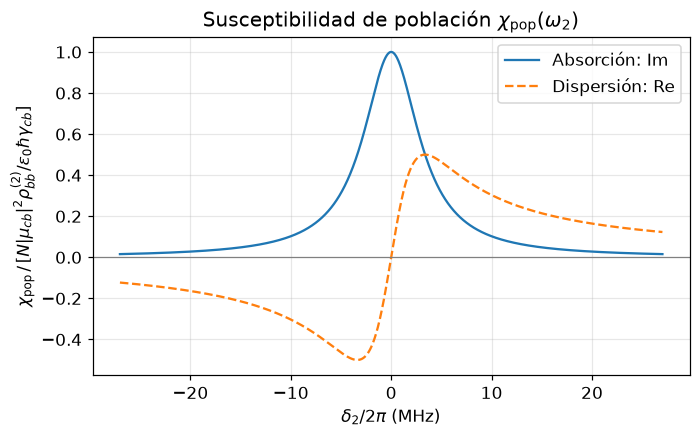

Guardada: figuras\F2_chipop_vs_delta2.pdf


In [6]:
verificar()
    
d2 = np.linspace(-N_ANCHOS * gamma_cb, N_ANCHOS * gamma_cb, N_PUNTOS)
chi_pop_norm = gamma_cb / (d2 - 1j * gamma_cb)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(d2, chi_pop_norm.imag, label="Absorción: Im")
ax.plot(d2, chi_pop_norm.real, ls="--", label="Dispersión: Re")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel(r"$\delta_2/2\pi$ (MHz)")
ax.set_ylabel(r"$\chi_{\mathrm{pop}}\,/\,[N|\mu_{cb}|^2\rho_{bb}^{(2)}/\varepsilon_0\hbar\gamma_{cb}]$")
ax.set_title(r"Susceptibilidad de población $\chi_{\mathrm{pop}}(\omega_2)$")
ax.legend()
plt.show()
guardar(fig, "F2_chipop_vs_delta2")

## 5. Figura F3 — Mapa de la absorción por población

**Cantidad.** La parte imaginaria de $\chi^{(3)}_{\text{pop}}$, (2.87), en función de las dos desintonías que se controlan:

$$
\chi^{(3)}_{\text{pop}} = \frac{2\gamma_{ba}}{\Gamma_{ab}}\,
\frac{K}{(\Delta_3^2+\gamma_{ba}^2)(\delta_2-i\gamma_{cb})},
\qquad K \equiv \frac{N\lvert\mu_{ba}\rvert^2\lvert\mu_{cb}\rvert^2}{\varepsilon_0\hbar^3}.
$$

**Normalización.** Se divide por $K/(\gamma_{ba}^2\gamma_{cb})$. La parte imaginaria queda como producto de dos lorentzianas:

$$
\frac{\mathrm{Im}\,\chi^{(3)}_{\text{pop}}}{K/\gamma_{ba}^2\gamma_{cb}}
= \frac{2\gamma_{ba}}{\Gamma_{ab}}\;L_{\gamma_{ba}}(\Delta_3)\;L_{\gamma_{cb}}(\Delta_2-\Delta_3).
$$

**Qué observar.** El primer factor dice que la absorción solo existe si la semilla está cerca de la línea D2 ($\Delta_3\approx0$). El segundo, que la señal debe estar cerca de su propia resonancia ($\delta_2\approx0$). La escala de color es logarítmica para que se vean ambas crestas.

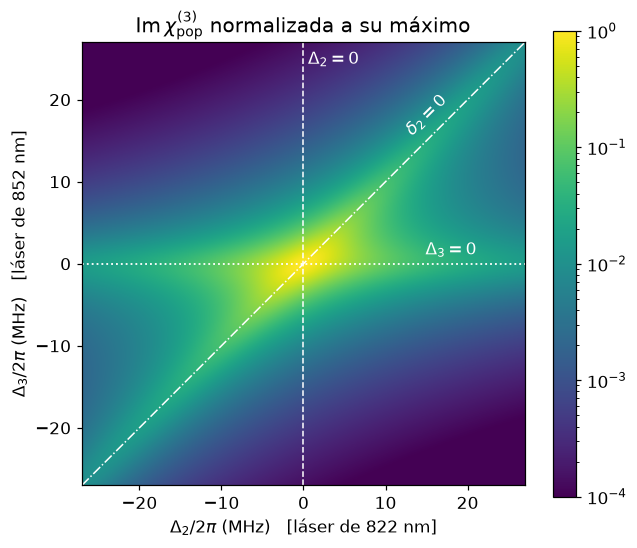

Guardada: figuras\F3_mapa_chipop.pdf


In [7]:
verificar()

lim = N_ANCHOS * max(gamma_ba, gamma_cb)
eje = np.linspace(-lim, lim, N_MAPA)
D2, D3 = np.meshgrid(eje, eje)

mapa = (2 * gamma_ba / Gamma_ab) * lorentziana(D3, gamma_ba) * lorentziana(delta2(D2, D3), gamma_cb)
mapa = mapa / mapa.max()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(mapa, origin="lower", extent=[-lim, lim, -lim, lim], aspect="equal",
               norm=LogNorm(vmin=1e-4, vmax=1))
marcar_rectas(ax, lim)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel(r"$\Delta_2/2\pi$ (MHz)   [láser de 822 nm]")
ax.set_ylabel(r"$\Delta_3/2\pi$ (MHz)   [láser de 852 nm]")
ax.set_title(r"$\mathrm{Im}\,\chi^{(3)}_{\mathrm{pop}}$ normalizada a su máximo")
ax.grid(False)
fig.colorbar(im, ax=ax)
plt.show()
guardar(fig, "F3_mapa_chipop")

## 6. Figura F4 — La susceptibilidad efectiva de la señal, término por término

**Cantidad.** La susceptibilidad efectiva que ve la señal en la Rama B (Tabla 2.1),

$$
\chi_{\text{ef}} = \chi^{(3)}_{X,B}\lvert\tilde E_3\rvert^2 + \chi_{\text{pop}}(\omega_2),
$$

con el término cruzado (2.85),

$$
\chi^{(3)}_{X,B}\lvert\tilde E_3\rvert^2 = -\frac{K\lvert\tilde E_3\rvert^2}{(\Delta_2-i\gamma_{ca})(\delta_2-i\gamma_{cb})}
\left[\frac{1}{\Delta_3-i\gamma_{ba}}+\frac{1}{2\Delta_1-\Delta_3-i\gamma_{ba}}\right],
$$

y el de población (2.87), $\chi_{\text{pop}} = \chi^{(3)}_{\text{pop}}\lvert\tilde E_3\rvert^2$.

**Normalización.** Ambos términos son proporcionales a $K\lvert\tilde E_3\rvert^2$; se divide por $K\lvert\tilde E_3\rvert^2/(\gamma_{ba}\gamma_{ca}\gamma_{cb})$. Así la figura no depende de la intensidad de la semilla.

**Barrido.** La semilla queda fija y se barre el bombeo ($\Delta_2$), de modo que $\delta_2=\Delta_2-\Delta_3$ cambia junto con él. Se muestran dos casos: semilla en resonancia ($\Delta_3=0$) y semilla desintonizada ($\Delta_3$ = `DELTA3_FIJA` $\times\,\gamma_{ba}$). La fila superior es la parte imaginaria (absorción) y la inferior la real (dispersión).

**Qué observar.** Cada término tiene resonancias en $\Delta_2=0$ y en $\delta_2=0$ (es decir, $\Delta_2=\Delta_3$); con la semilla en resonancia ambas coinciden. La suma no tiene por qué parecerse a la superposición de las curvas de cada término por separado: se suman amplitudes complejas, no intensidades.

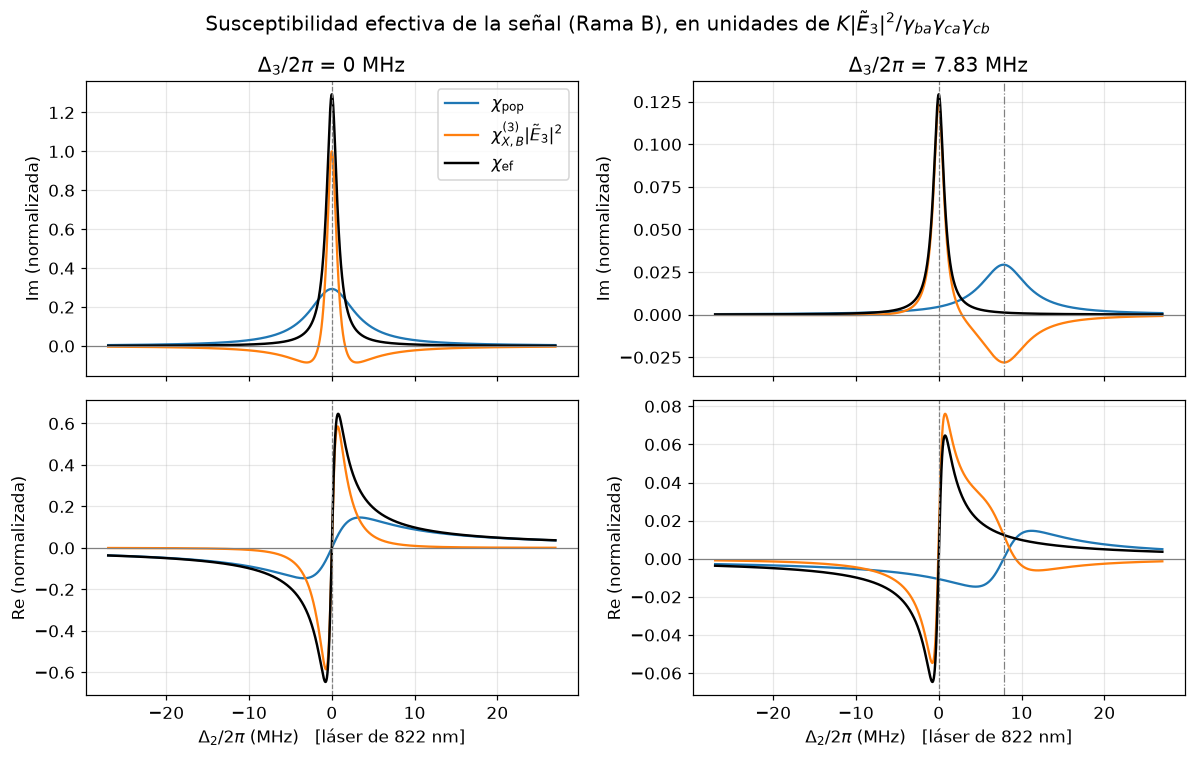

Guardada: figuras\F4_chief_terminos.pdf


In [8]:
verificar()

def chi_X_norm(D2, D3):
    # χ_X,B |E3|^2 normalizada por K|E3|^2/(γ_ba γ_ca γ_cb), ec. (2.85).
    D1, d2 = desintonias(D2, D3)
    corchete = 1 / (D3 - 1j * gamma_ba) + 1 / (2 * D1 - D3 - 1j * gamma_ba)
    return -(gamma_ba * gamma_ca * gamma_cb) * corchete / (
        (D2 - 1j * gamma_ca) * (d2 - 1j * gamma_cb))

def chi_pop_norm(D2, D3):
    # χ_pop normalizada por K|E3|^2/(γ_ba γ_ca γ_cb), ec. (2.87).
    return (2 * gamma_ba / Gamma_ab) * (gamma_ba * gamma_ca * gamma_cb) / (
        (D3**2 + gamma_ba**2) * (delta2(D2, D3) - 1j * gamma_cb))

casos = [0.0, DELTA3_FIJA * gamma_ba]
lim = N_ANCHOS * max(gamma_ba, gamma_ca, gamma_cb)
D2 = np.linspace(-lim, lim, N_PUNTOS)

fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for col, D3 in enumerate(casos):
    cx, cp = chi_X_norm(D2, D3), chi_pop_norm(D2, D3)
    for fila, parte, nombre in [(0, np.imag, "Im"), (1, np.real, "Re")]:
        ax = axs[fila, col]
        ax.plot(D2, parte(cp), label=r"$\chi_{\mathrm{pop}}$")
        ax.plot(D2, parte(cx), label=r"$\chi^{(3)}_{X,B}|\tilde E_3|^2$")
        ax.plot(D2, parte(cp + cx), "k", lw=1.6, label=r"$\chi_{\mathrm{ef}}$")
        ax.axhline(0, color="gray", lw=0.8)
        ax.axvline(0, color="gray", ls="--", lw=0.8)      # Δ2 = 0
        if D3 != 0:
            ax.axvline(D3, color="gray", ls="-.", lw=0.8)  # δ2 = 0
        ax.set_ylabel(f"{nombre} (normalizada)")
    axs[0, col].set_title(rf"$\Delta_3/2\pi$ = {D3:.3g} MHz")
    axs[1, col].set_xlabel(r"$\Delta_2/2\pi$ (MHz)   [láser de 822 nm]")
axs[0, 0].legend()
fig.suptitle(r"Susceptibilidad efectiva de la señal (Rama B), en unidades de $K|\tilde E_3|^2/\gamma_{ba}\gamma_{ca}\gamma_{cb}$")
fig.tight_layout()
plt.show()
guardar(fig, "F4_chief_terminos")

## 7. Figura F5 — Módulo y fase de la fuente $\chi^{(3)}_{P,B}$

**Cantidad.** La susceptibilidad paramétrica de la Rama B, (2.84),

$$
\chi^{(3)}_{P,B} = -\frac{K}{(\Delta_1-i\gamma_{ba})(\Delta_2-i\gamma_{ca})(\delta_2-i\gamma_{cb})} .
$$

Se grafica como susceptibilidad: su módulo y su fase. No se afirma nada sobre la intensidad de la señal generada; eso corresponde al Capítulo 3.

**Normalización.** Se divide por $K/(\lvert\Delta_1\rvert\gamma_{ca}\gamma_{cb})$. $\Delta_1$ se calcula en cada punto con `desintonias`; en el rango barrido cambia en una parte en $10^{6}$, así que la normalización es prácticamente constante. Como $\lvert\Delta_1\rvert\gg\gamma_{ba}$, el primer factor contribuye prácticamente solo con su signo, que es una fase constante de $0$ o $\pi$:

$$
\frac{\chi^{(3)}_{P,B}}{K/\lvert\Delta_1\rvert\gamma_{ca}\gamma_{cb}}
= -\frac{\lvert\Delta_1\rvert}{\Delta_1-i\gamma_{ba}}\;
\frac{\gamma_{ca}\gamma_{cb}}{(\Delta_2-i\gamma_{ca})(\delta_2-i\gamma_{cb})} .
$$

**Barridos.**

- (a) Bombeo barrido con la semilla en resonancia, $\Delta_3=0$. Entonces $\delta_2=\Delta_2$, y las dos resonancias restantes coinciden.
- (b) Semilla barrida con el bombeo en resonancia de dos fotones, $\Delta_2=0$. Entonces $\delta_2=-\Delta_3$: el ancho de esta curva lo fija $\gamma_{cb}$, no $\gamma_{ba}$, porque la semilla no aparece en ningún denominador de $\chi^{(3)}_{P,B}$ salvo a través de $\delta_2$.

**Qué observar.** La fase importa porque en el Capítulo 3 la fuente se compara con $\chi_{\text{ef}}$ a la misma frecuencia (ver el comentario sobre el signo global tras (2.84)). La fase se muestra en unidades de $\pi$.

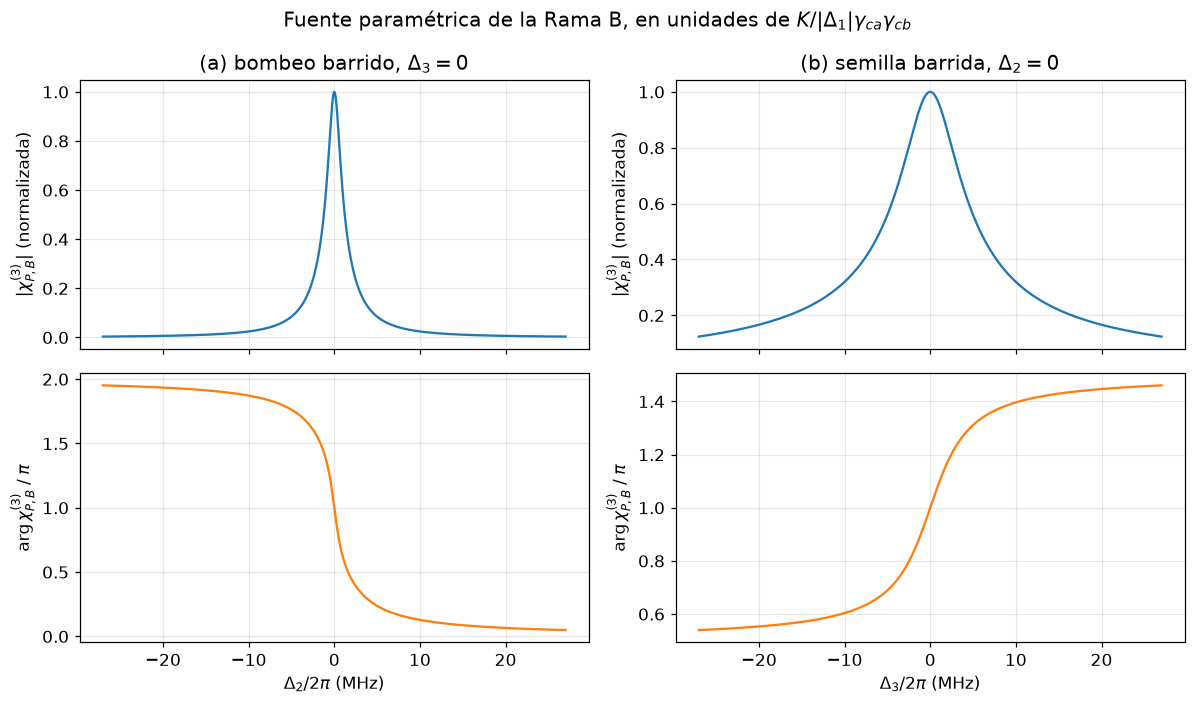

Guardada: figuras\F5_chiP_modulo_fase.pdf


In [9]:
verificar()

def chi_P_norm(D2, D3):
    # χ_P,B normalizada por K/(|Δ1| γ_ca γ_cb), ec. (2.84).
    D1, d2 = desintonias(D2, D3)
    return -(abs(D1) / (D1 - 1j * gamma_ba)) * (gamma_ca * gamma_cb) / (
        (D2 - 1j * gamma_ca) * (d2 - 1j * gamma_cb))

lim = N_ANCHOS * max(gamma_ca, gamma_cb)
x = np.linspace(-lim, lim, N_PUNTOS)
barridos = [
    (chi_P_norm(x, 0.0), r"$\Delta_2/2\pi$ (MHz)", r"(a) bombeo barrido, $\Delta_3=0$"),
    (chi_P_norm(0.0, x), r"$\Delta_3/2\pi$ (MHz)", r"(b) semilla barrida, $\Delta_2=0$"),
]

fig, axs = plt.subplots(2, 2, figsize=(11, 6.5), sharex="col")
for col, (chi, etiqueta_x, titulo) in enumerate(barridos):
    axs[0, col].plot(x, np.abs(chi))
    axs[0, col].set_title(titulo)
    axs[0, col].set_ylabel(r"$|\chi^{(3)}_{P,B}|$ (normalizada)")
    axs[1, col].plot(x, np.unwrap(np.angle(chi)) / np.pi if col==1 else (np.unwrap(np.angle(chi)) + 2*np.pi) / np.pi, color="C1")
    axs[1, col].set_ylabel(r"$\arg\chi^{(3)}_{P,B}\;/\;\pi$")
    axs[1, col].set_xlabel(etiqueta_x)
fig.suptitle(r"Fuente paramétrica de la Rama B, en unidades de $K/|\Delta_1|\gamma_{ca}\gamma_{cb}$")
fig.tight_layout()
plt.show()
guardar(fig, "F5_chiP_modulo_fase")